<div style="text-align: center;"><h1 style="margin-bottom: 10px; font-weight: bold;">SHAP EXPLAINABILITY</h1></div>

## Objective

Explain the key features influencing employee attrition predictions using SHAP.

## Import Dataset

In [14]:
import pandas as pd
df = pd.read_csv("../data/processed/hr_employee_master.csv")

## Load Trained Model

In [2]:
import joblib

rf = joblib.load("../models/random_forest_pipeline.pkl")
print("Random Forest model loaded successfully.")

Random Forest model loaded successfully.


## Prepare Test Data

In [3]:
drop_cols = ["EmployeeID", "Tenure_Group", "Promotion_Group", "Manager_Tenure_Group"]
drop_cols = [col for col in drop_cols if col in df.columns]

X = df.drop(columns=["Attrition"] + drop_cols)
y = df["Attrition"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

## SHAP Explainer

In [7]:
import shap
import matplotlib.pyplot as plt

X_test_transformed = rf.named_steps["preprocessor"].transform(X_test)
feature_names = rf.named_steps["preprocessor"].get_feature_names_out()

In [8]:
explainer = shap.TreeExplainer(rf.named_steps["model"])
shap_values = explainer.shap_values(X_test_transformed)

## Global Feature Importance

In [9]:
if isinstance(shap_values, list):
    values = shap_values[1]
else:
    values = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": abs(values).mean(axis=0)
    })
    .sort_values("Importance", ascending=False)
    .head(15)
)

feature_importance

,Feature,Importance
26,num__Age,0.051055
36,num__YearsAtCompany,0.043130
34,num__TotalWorkingYears,0.040226
38,num__YearsWithCurrManager,0.037658
25,cat__MaritalStatus_Single,0.034997
39,num__EnvironmentSatisfaction,0.032178
40,num__JobSatisfaction,0.025295
30,num__MonthlyIncome,0.023312
31,num__NumCompaniesWorked,0.023207
27,num__DistanceFromHome,0.019340


## SHAP Summary Plot

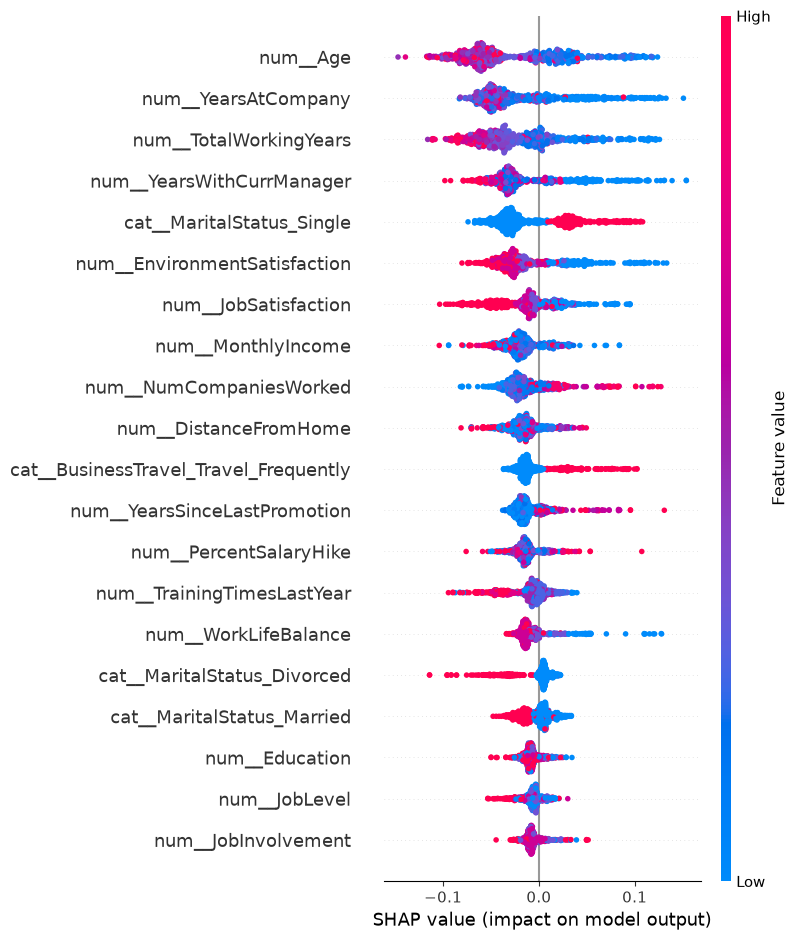

In [10]:
shap.summary_plot(
    values,
    X_test_transformed,
    feature_names=feature_names
)

The SHAP summary plot shows that Age, YearsAtCompany, TotalWorkingYears, and YearsWithCurrManager have the strongest overall influence on attrition predictions.

## Individual Prediction Explanation

In [11]:
sample = X_test.iloc[[0]]
prediction = rf.predict(sample)[0]

print("Predicted Attrition:", prediction)

Predicted Attrition: No


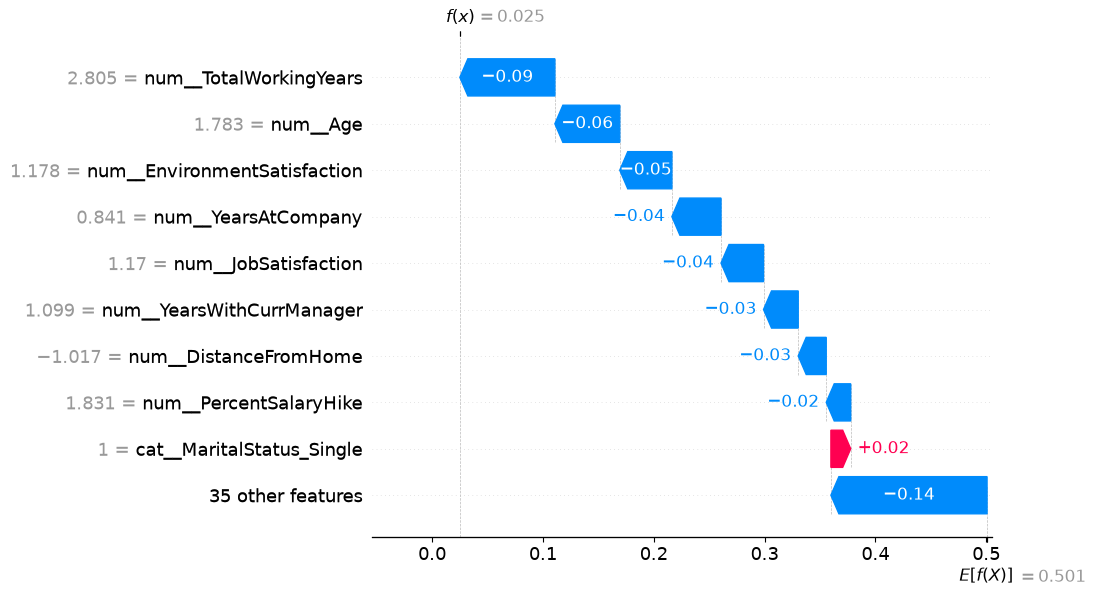

In [13]:
sample_values = values[0]
sample_data = X_test_transformed[0]

base_value = explainer.expected_value[1]

shap.waterfall_plot(
    shap.Explanation(
        values=sample_values,
        base_values=base_value,
        data=sample_data,
        feature_names=feature_names
    ),
    max_display=10
)

## Conclusion

SHAP analysis identified the key features influencing employee attrition predictions and provided both global and individual-level model explanations.